## PROJECT: Instacart Customer Purchase Analysis: Data Wrangling & Business Insights

# Description:

This project focuses on cleaning, preparing, and analyzing customer order data from Instacart to uncover purchasing patterns and shopping behaviors. The data wrangling process includes handling missing values, removing duplicates, and validating data quality to ensure accurate analysis.

After preparing the dataset, an exploratory data analysis (EDA) is conducted to identify trends such as peak ordering times, reorder behavior, and the most popular products and departments. The project demonstrates how raw data can be transformed into actionable business insights through data cleaning, visualization, and analytical techniques using Python.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# LOAD DATA
aisles = pd.read_csv('aisles.csv', sep=';')
departments = pd.read_csv('departments.csv', sep=';')
instacart_orders = pd.read_csv('instacart_orders.csv', sep=';')
order_products = pd.read_csv('order_products.csv', sep=';')
products = pd.read_csv('products.csv', sep=';')

In [3]:
aisles.info()
aisles.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134 entries, 0 to 133
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   aisle_id  134 non-null    int64 
 1   aisle     134 non-null    object
dtypes: int64(1), object(1)
memory usage: 2.2+ KB


,aisle_id,aisle
0,1,prepared soups salads
1,2,specialty cheeses
2,3,energy granola bars
3,4,instant foods
4,5,marinades meat preparation


In [4]:
departments.info()
departments.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   department_id  21 non-null     int64 
 1   department     21 non-null     object
dtypes: int64(1), object(1)
memory usage: 468.0+ bytes


,department_id,department
0,1,frozen
1,2,other
2,3,bakery
3,4,produce
4,5,alcohol


In [5]:
instacart_orders.info()
instacart_orders.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 478967 entries, 0 to 478966
Data columns (total 6 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   order_id                478967 non-null  int64  
 1   user_id                 478967 non-null  int64  
 2   order_number            478967 non-null  int64  
 3   order_dow               478967 non-null  int64  
 4   order_hour_of_day       478967 non-null  int64  
 5   days_since_prior_order  450148 non-null  float64
dtypes: float64(1), int64(5)
memory usage: 21.9 MB


,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,1515936,183418,11,6,13,30.0
1,1690866,163593,5,5,12,9.0
2,1454967,39980,4,5,19,2.0
3,1768857,82516,56,0,20,10.0
4,3007858,196724,2,4,12,17.0


In [6]:
order_products.info(show_counts=True)
order_products.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4545007 entries, 0 to 4545006
Data columns (total 4 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   order_id           4545007 non-null  int64  
 1   product_id         4545007 non-null  int64  
 2   add_to_cart_order  4544171 non-null  float64
 3   reordered          4545007 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 138.7 MB


,order_id,product_id,add_to_cart_order,reordered
0,2141543,11440,17.0,0
1,567889,1560,1.0,1
2,2261212,26683,1.0,1
3,491251,8670,35.0,1
4,2571142,1940,5.0,1


In [7]:
products.info()
products.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49694 entries, 0 to 49693
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   product_id     49694 non-null  int64 
 1   product_name   48436 non-null  object
 2   aisle_id       49694 non-null  int64 
 3   department_id  49694 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 1.5+ MB


,product_id,product_name,aisle_id,department_id
0,1,Chocolate Sandwich Cookies,61,19
1,2,All-Seasons Salt,104,13
2,3,Robust Golden Unsweetened Oolong Tea,94,7
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,38,1
4,5,Green Chile Anytime Sauce,5,13


Initial Data Observations

1. Aisles contains 134 records with no missing values. All columns have the appropriate data types, indicating that the dataset is complete and ready for analysis.

2. Departments contains 21 records with no missing values. The data types are correctly assigned, and no immediate data quality issues were identified.

3. Instacart Orders contains 478,967 records. The days_since_prior_order column includes 28,819 missing values, which may correspond to customers placing their first order. All other columns have appropriate data types.

4. Order Products contains 4,545,007 records. The add_to_cart_order column has 836 missing values, which will require further investigation to determine their impact on the analysis. The data types are correctly configured.

5. Products contains 49,694 records. The product_name column includes 1,258 missing values, which may affect product-level analyses and should be addressed during data preprocessing. All columns have appropriate data types.

In [8]:
# Data Wrangling : Handling Duplicate Values
Duplicate_aisles = aisles.duplicated().sum()
print(f'Number of Explicit Duplicate aisles: {Duplicate_aisles}')

Duplicate_departments = departments.duplicated().sum()
print(f'Number of Explicit Duplicate departments: {Duplicate_departments}')

Duplicate_instacart_orders = instacart_orders.duplicated().sum()
print(f'Number of Explicit Duplicate instacart_orders: {Duplicate_instacart_orders}')

Duplicate_order_products = order_products.duplicated().sum()
print(f'Number of Explicit Duplicate order_products: {Duplicate_order_products}')

Duplicate_products = products.duplicated().sum()
print(f'Number of Explicit Duplicate products: {Duplicate_products}')


Number of Explicit Duplicate aisles: 0
Number of Explicit Duplicate departments: 0
Number of Explicit Duplicate instacart_orders: 15
Number of Explicit Duplicate order_products: 0
Number of Explicit Duplicate products: 0


In [9]:
instacart_orders[instacart_orders.duplicated()]

instacart_orders_without_duplicates = instacart_orders.drop_duplicates().reset_index(drop=True)

instacart_orders_without_duplicates.duplicated().sum()

np.int64(0)

In [10]:
departments_id = departments['department_id'].duplicated().sum()
print(f'Number of duplicate department_id: {departments_id}')

aisles_id = aisles['aisle_id'].duplicated().sum()
print(f'Number of duplicate aisle_id: {aisles_id}')

order_products_id = order_products[['order_id', 'product_id']].duplicated().sum()
print(f'Number of duplicate order_product combinations: {order_products_id}')

products_id = products['product_id'].duplicated().sum()
print(f'Number of duplicate product_id: {products_id}')

Number of duplicate department_id: 0
Number of duplicate aisle_id: 0
Number of duplicate order_product combinations: 0
Number of duplicate product_id: 0


Duplicate Values Assessment

During the data cleaning process, several checks were performed to identify and handle duplicate records across the datasets.

1. Instacart Orders: All fully duplicated rows were identified and removed to ensure data consistency and prevent duplicated transactions from affecting the analysis.

2. Departments, Aisles, products and Order Products: No duplicated IDs were found in these datasets, indicating that the primary identifiers are unique and the data integrity has been maintained.

Summary

The duplicate analysis revealed that the main data quality issues were concentrated in the Instacart Orders and Products datasets. Removing fully duplicated records and standardizing product names improved data consistency and enabled a more accurate assessment of duplicate entries. The remaining datasets showed no duplicated identifiers, suggesting a high level of structural integrity.

In [11]:
aisles_missing_values = aisles.isna().sum()
print(f'Missing values in aisles: {aisles_missing_values}')
print('----------------------------------------------------')
departments_missing_values = departments.isna().sum()
print(f'Missing values in departments: {departments_missing_values}')
print('----------------------------------------------------')
instacart_orders_missing_values = instacart_orders_without_duplicates.isna().sum()
print(f'Missing values in instacart_orders: {instacart_orders_missing_values}')
print('----------------------------------------------------')
order_products_missing_values = order_products.isna().sum()
print(f'Missing values in order_products: {order_products_missing_values}')
print('----------------------------------------------------')
products_missing_values = products.isna().sum()
print(f'Missing values in products: {products_missing_values}')

Missing values in aisles: aisle_id    0
aisle       0
dtype: int64
----------------------------------------------------
Missing values in departments: department_id    0
department       0
dtype: int64
----------------------------------------------------
Missing values in instacart_orders: order_id                      0
user_id                       0
order_number                  0
order_dow                     0
order_hour_of_day             0
days_since_prior_order    28817
dtype: int64
----------------------------------------------------
Missing values in order_products: order_id               0
product_id             0
add_to_cart_order    836
reordered              0
dtype: int64
----------------------------------------------------
Missing values in products: product_id          0
product_name     1258
aisle_id            0
department_id       0
dtype: int64


In [12]:

Null_Values = instacart_orders[instacart_orders['days_since_prior_order'].isnull()]

Null_Values['order_number'].unique()

instacart_orders_without_duplicates['days_since_prior_order'] = instacart_orders_without_duplicates['days_since_prior_order'].fillna('NaN')


In [13]:
instacart_orders_missing_values = instacart_orders_without_duplicates.isna().sum()
print(f'Missing values in instacart_orders: {instacart_orders_missing_values}')

Missing values in instacart_orders: order_id                  0
user_id                   0
order_number              0
order_dow                 0
order_hour_of_day         0
days_since_prior_order    0
dtype: int64


In [14]:
print(f"Valor mínimo: {order_products['add_to_cart_order'].min()}")
print(f"Valor máximo: {order_products['add_to_cart_order'].max()}")

missing_orders = order_products[order_products['add_to_cart_order'].isna()]

product_counts = missing_orders.groupby('order_id')['product_id'].count()
print(product_counts)

Valor mínimo: 1.0
Valor máximo: 64.0
order_id
9310        1
61355      63
102236     31
129627      5
165801      6
           ..
2999801     6
3125735    22
3308010    51
3347453     7
3383594     5
Name: product_id, Length: 70, dtype: int64


In [15]:
order_products['add_to_cart_order'].fillna(999).astype(int)

0          17
1           1
2           1
3          35
4           5
           ..
4545002    12
4545003     9
4545004     4
4545005     8
4545006     9
Name: add_to_cart_order, Length: 4545007, dtype: int64

In [16]:
# The first observation of the missing values ​​in the product name is related to aisle 10 and department 21.
Products_without_names = products[products['product_name'].isna()]
print(f"Aisle IDs without names: {Products_without_names['aisle_id'].unique()}")
print(f"Department IDs without names: {Products_without_names['department_id'].unique()}")

print('-----------------------------------------------------')

# Dataframe department and aisle to review data of aisle with id 100 and department with id 21
aisle_100 = aisles[aisles['aisle_id'] == 100]
print(aisle_100)

department_21 = departments[departments['department_id'] == 21]
print(department_21)

Aisle IDs without names: [100]
Department IDs without names: [21]
-----------------------------------------------------
    aisle_id    aisle
99       100  missing
    department_id department
20             21    missing


In [17]:
products['product_name'] = products['product_name'].fillna('Unknown')

Missing Values Assessment
Products Dataset

The missing values in the product_name column were investigated and found to be consistently associated with aisle_id 100 and department_id 21. Since the corresponding records in the related datasets did not provide additional information to identify these products, removing them could have resulted in the loss of valid sales transactions and potentially biased the analysis.

To preserve data integrity, the missing product names were replaced with the placeholder value "Unknown" using fillna('Unknown'). This approach retains all transaction records while clearly identifying products with unavailable descriptions.

Order Products Dataset

The add_to_cart_order column represents the sequence in which items were added to a customer's cart. A minimum value of 1 is expected, as every order must contain at least one item. However, a maximum value of 64 appeared unusually consistent and raised concerns regarding potential system or storage limitations.

Further investigation revealed that every order associated with a missing add_to_cart_order value contained more than 64 products. This pattern suggests that the missing values may be related to a technical limitation in recording the cart position for large orders.

Because it is impossible to determine the true cart position of the affected products, the missing values were replaced with a placeholder value of 999. This value clearly distinguishes imputed records from valid cart positions and prevents them from being misinterpreted as actual ordering sequences during analysis.

Instacart Orders Dataset

All 28,819 missing values in the days_since_prior_order column correspond to customers' first recorded orders. This is an expected and logical occurrence because a customer's first order does not have a previous order from which a time interval can be calculated.

Therefore, these missing values were considered structurally missing rather than data quality issues, and no further correction was required.

Summary

The missing value analysis showed that most absent data can be explained by the structure and behavior of the underlying system. Product names with unavailable descriptions were preserved using the label "Unknown", missing cart positions were assigned a placeholder value 999 to maintain analytical consistency, and missing values in days_since_prior_order were confirmed to represent customers' first purchases, making them both expected and informative.

In [18]:
#Variables that were cleaned, duplicate values, missing values, and have the correct data types
# 1. products
# 2. instacart_orders_missing_values
# 3. order_products
# 4. aisles
# 5. departments

Data Analysis



## 1. Validation of Values in order_hour_of_day and order_dow

# Objective

The purpose of this analysis is to verify that the values in the order_hour_of_day and order_dow columns of the instacart_orders dataset fall within the expected ranges. According to the dataset documentation, order_hour_of_day should contain values from 0 to 23, representing the hours of the day, while order_dow should contain values from 0 to 6, representing the days of the week.

In [ ]:
#Analysis: To validate the consistency of these variables, the minimum and maximum values for each column were examined using the following code:

print(instacart_orders['order_hour_of_day'].max())
print(instacart_orders['order_hour_of_day'].min())

print(instacart_orders['order_dow'].max())
print(instacart_orders['order_dow'].min())

# It is verified that the columns order_hour_of_day have 24 hours and order_down have the correct days. 


23
0
6
0


# The results showed that:

order_hour_of_day has a minimum value of 0 and a maximum value of 23.
order_dow has a minimum value of 0 and a maximum value of 6.

These findings confirm that all values fall within the expected ranges defined by the dataset and that no invalid values were detected in either column.

Conclusion

The validation process confirmed that both order_hour_of_day and order_dow contain reasonable and consistent values. The order hours correctly span the full 24-hour period (0-23), and the day-of-week values are limited to the expected range (0-6). Therefore, these variables are reliable and suitable for subsequent analyses involving customers' purchasing behavior and ordering patterns over time.

## 2. Number of Orders by Hour of the Day

# Objective

Examine how order activity varies throughout the day by identifying the hours when customers place the greatest and lowest number of orders. Understanding these patterns provides insight into customer shopping behavior and peak ordering periods.

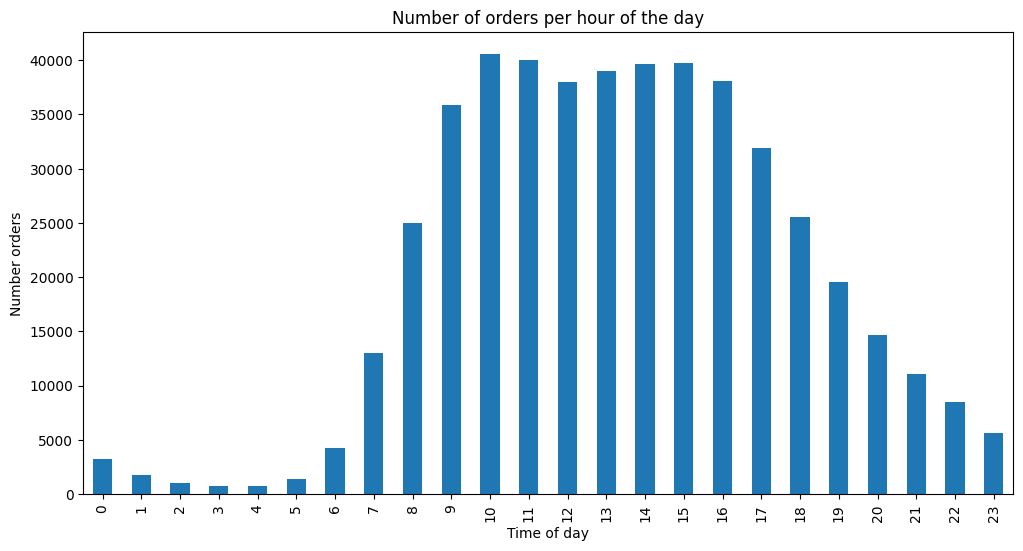

In [ ]:
# Analysis: To analyze ordering activity by hour, the frequency of orders was calculated for each value in the order_hour_of_day column and visualized using a bar chart.

orders_by_hour = instacart_orders['order_hour_of_day'].value_counts().sort_index()

orders_by_hour.plot(title="Number of orders per hour of the day",
                    kind='bar',
                    xlabel="Time of day",
                    ylabel= "Number orders",
                    figsize=[12,6])
plt.show()

The chart shows a clear daily ordering pattern. Order activity is very low during the early morning hours, particularly between 2:00 AM and 5:00 AM, when most customers are not actively shopping. Starting around 7:00 AM, the number of orders increases rapidly.

The highest concentration of orders occurs between approximately 10:00 AM and 4:00 PM, with a peak around 10:00 AM to 11:00 AM. During these hours, customer activity remains consistently high, indicating that late morning and early afternoon are the most popular times for placing orders.

After 5:00 PM, the number of orders gradually declines, and activity continues to decrease throughout the evening and night.

# Conclusion

The analysis reveals that customer ordering behavior follows a predictable daily pattern. Most orders are placed during daytime hours, with peak activity occurring between late morning and early afternoon. In contrast, very few orders are submitted during the overnight and early morning hours. These findings suggest that customers primarily use the platform during regular waking hours, making midday the most active period for order placement.

## Which Day of the Week Do Customers Place Their Orders?

# Objective

Identify purchasing patterns throughout the week by examining the number of orders placed on each day. Understanding which days generate the highest and lowest order volumes can provide insights into customer shopping habits and demand trends

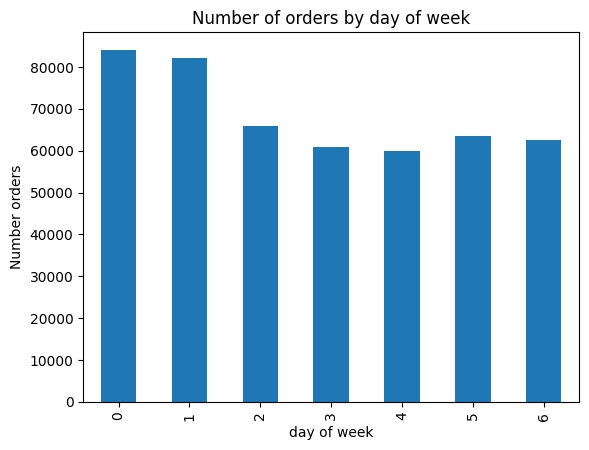

In [ ]:
# Analysis : To determine how orders are distributed across the week, the frequency of each value in the order_dow column was calculated and displayed using a bar chart

orders_by_day = instacart_orders['order_dow'].value_counts().sort_index()

orders_by_day.plot(title="Number of orders by day of week",
                   kind="bar",
                   xlabel='day of week',
                   ylabel='Number orders',
                   )
plt.show()

The chart shows that order activity is not evenly distributed throughout the week. The highest number of orders occurs on days 0 and 1, which stand out significantly compared to the remaining days. After these peaks, order volume decreases and remains relatively stable during the rest of the week.

Days 3 and 4 have the lowest number of orders, while days 5 and 6 show a moderate increase compared to the middle of the week. Overall, the differences suggest that customers tend to concentrate their shopping activity at the beginning of the weekly cycle rather than distributing purchases evenly across all days.

# Conclusion

The analysis indicates that customer purchasing behavior varies throughout the week, with the largest number of orders placed on days 0 and 1. Order activity declines during the middle of the week and remains relatively consistent afterward. These findings suggest that customers are more likely to place orders at the start of the week, making these days the busiest periods for the platform.

## Time Between Consecutive Orders

# Objective

Examine how long customers typically wait before placing their next order. By analyzing the days_since_prior_order variable, it is possible to identify common purchasing intervals and better understand customer reordering behavior.

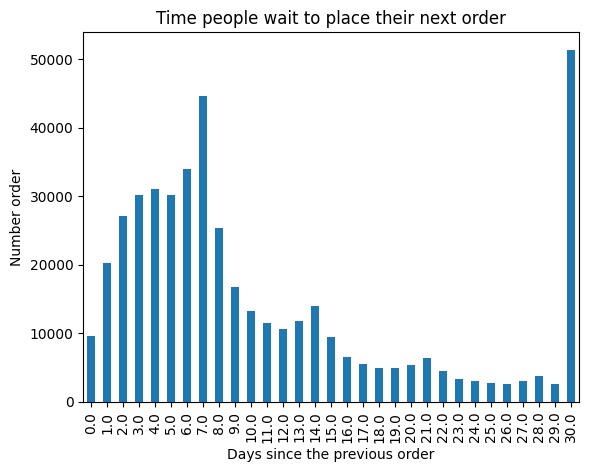

In [ ]:
# Analysis: To evaluate the time elapsed between orders, the frequency of each value in the days_since_prior_order column was calculated and visualized using a bar chart.

time_to_do_next_order = instacart_orders['days_since_prior_order'].value_counts().sort_index()

time_to_do_next_order.plot(title="Time people wait to place their next order",
                           kind='bar',
                           xlabel="Days since the previous order",
                           ylabel='Number order')
plt.show()

The distribution reveals that customers most commonly place a new order after 7 days, suggesting a strong weekly purchasing pattern. Another notable peak appears at 30 days, indicating that a significant group of customers tends to shop approximately once per month.

Order frequencies are relatively high during the first week following a purchase and gradually decline as the number of days increases. However, the substantial increase at 30 days stands out from the overall trend and may reflect customers who follow a monthly shopping routine.

Regarding the range of values:

The minimum value is 0 days, indicating that some customers placed another order on the same day as their previous purchase.
The maximum value is 30 days, meaning that the dataset records waiting periods of up to 30 days between consecutive orders.

# Conclusion

The analysis shows that customer purchasing behavior is largely driven by recurring schedules. The most common interval between orders is 7 days, indicating that many customers shop weekly. Additionally, the large number of orders occurring after 30 days suggests the presence of a second group of customers with monthly purchasing habits. Overall, the distribution highlights clear weekly and monthly ordering cycles, providing valuable insights into customer retention and shopping frequency patterns.

## Are There Differences in Order Patterns Between Wednesdays and Saturdays?

# Objective

The purpose of this analysis is to compare the distribution of orders throughout the day on Wednesdays (day 3) and Saturdays (day 6). By examining hourly order volumes for both days, it is possible to identify differences in customer purchasing behavior and determine whether shopping activity follows similar patterns across the week.

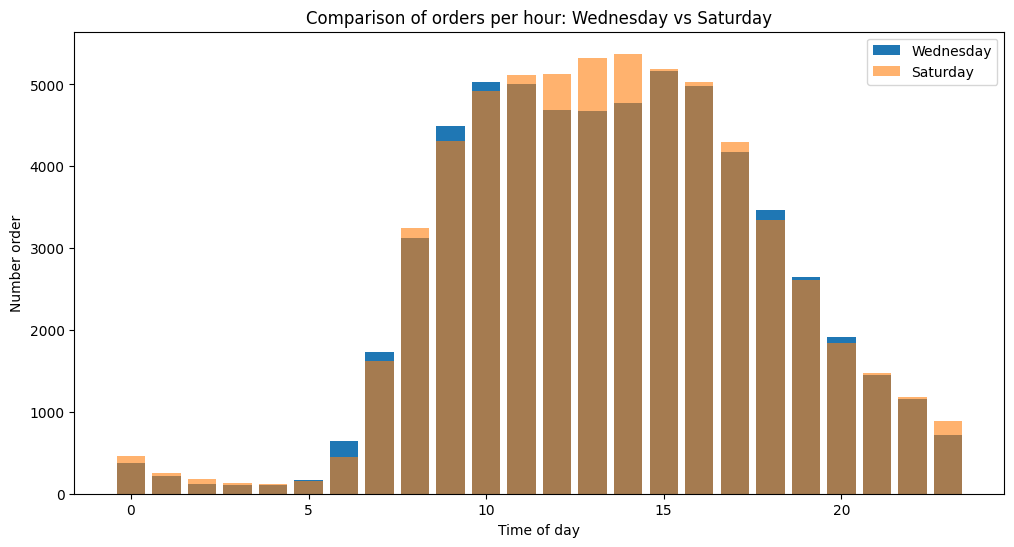

In [ ]:
# Analysis: To compare order activity, orders placed on Wednesdays and Saturdays were filtered from the dataset. The number of orders for each hour of the day was then calculated and displayed on the same chart.

wednesday_order = instacart_orders[instacart_orders['order_dow'] == 3]

saturday_order = instacart_orders[instacart_orders['order_dow'] == 6]

wednesday_hour_order = wednesday_order['order_hour_of_day'].value_counts().sort_index()
saturday_hour_order = saturday_order['order_hour_of_day'].value_counts().sort_index()

plt.figure(figsize=(12, 6))
plt.bar(wednesday_hour_order.index, wednesday_hour_order.values, label='Wednesday')
plt.bar(saturday_hour_order.index, saturday_hour_order.values, alpha=0.6, label='Saturday')
plt.title('Comparison of orders per hour: Wednesday vs Saturday')
plt.xlabel('Time of day')
plt.ylabel('Number order')
plt.legend()
plt.show()

The chart shows that both days follow a very similar pattern. Order activity is low during the early morning hours, increases steadily after approximately 7:00 AM, reaches its highest levels between 10:00 AM and 4:00 PM, and then gradually declines during the evening.

Although the overall distributions are similar, some differences can be observed. Saturday generally records a slightly higher number of orders during the midday and early afternoon hours, particularly between 11:00 AM and 3:00 PM. In contrast, Wednesday shows marginally higher activity during a few morning and evening periods. However, these differences are relatively small, and both days exhibit nearly identical customer ordering behavior.

# Conclusion

The comparison indicates that customer purchasing patterns on Wednesdays and Saturdays are highly consistent. Both days experience peak ordering activity during late morning and early afternoon hours, while overnight periods remain the least active. Although Saturdays show a slightly higher concentration of orders around midday, the overall distributions are very similar, suggesting that customers tend to place orders at comparable times regardless of whether it is a weekday or a weekend.

## Distribution of the Number of Orders per Customer

# Objective

The purpose of this analysis is to examine how many orders customers place over time and identify whether purchasing activity is concentrated among occasional shoppers or repeat customers. Understanding this distribution provides insight into customer retention and engagement with the platform.

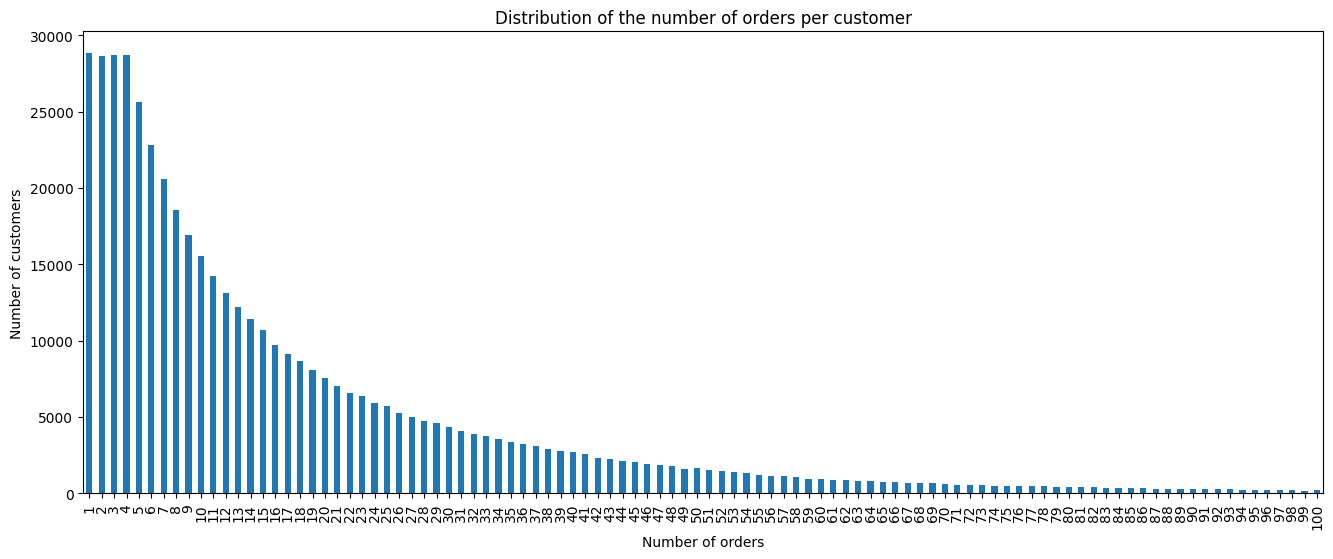

In [ ]:
# Analysis: To analyze customer ordering behavior, the total number of orders placed by each customer was calculated and visualized using a bar chart. The chart displays how many customers placed exactly one order, two orders, three orders, and so on.

distribution_of_the_number_of_orders.plot(kind='bar', 
                         title='Distribution of the number of orders per customer',
                         xlabel='Number of orders',
                         ylabel='Number of customers',
                         figsize=(16, 6))
plt.show()

The distribution is strongly right-skewed. The largest groups of customers are concentrated among those who placed only a small number of orders, particularly between one and five orders. As the number of orders increases, the number of customers decreases steadily.

Although a smaller group of customers placed dozens of orders, the frequency of these highly active customers is significantly lower than that of customers with only a few purchases. The long tail extending toward higher order counts indicates that some customers remain highly engaged with the platform and make recurring purchases over an extended period.

This pattern is common in e-commerce businesses, where a large portion of users are occasional shoppers while a smaller segment generates a substantial number of repeat orders.

# Conclusion

The analysis shows that most customers place relatively few orders, while the number of customers decreases progressively as the order count increases. The distribution is heavily skewed toward lower order frequencies, indicating that occasional purchasers represent the majority of the customer base. However, the presence of customers with a high number of orders suggests strong retention among a smaller group of loyal and highly engaged users. This behavior highlights the importance of repeat customers as a valuable segment for sustaining long-term platform activity.

## What Are the Top 20 Most Frequently Ordered Products?

# Objective

The purpose of this analysis is to identify the products that are ordered most frequently across all customer purchases. Understanding which products appear most often in orders helps reveal customer preferences and highlights the products that drive the highest demand on the platform.

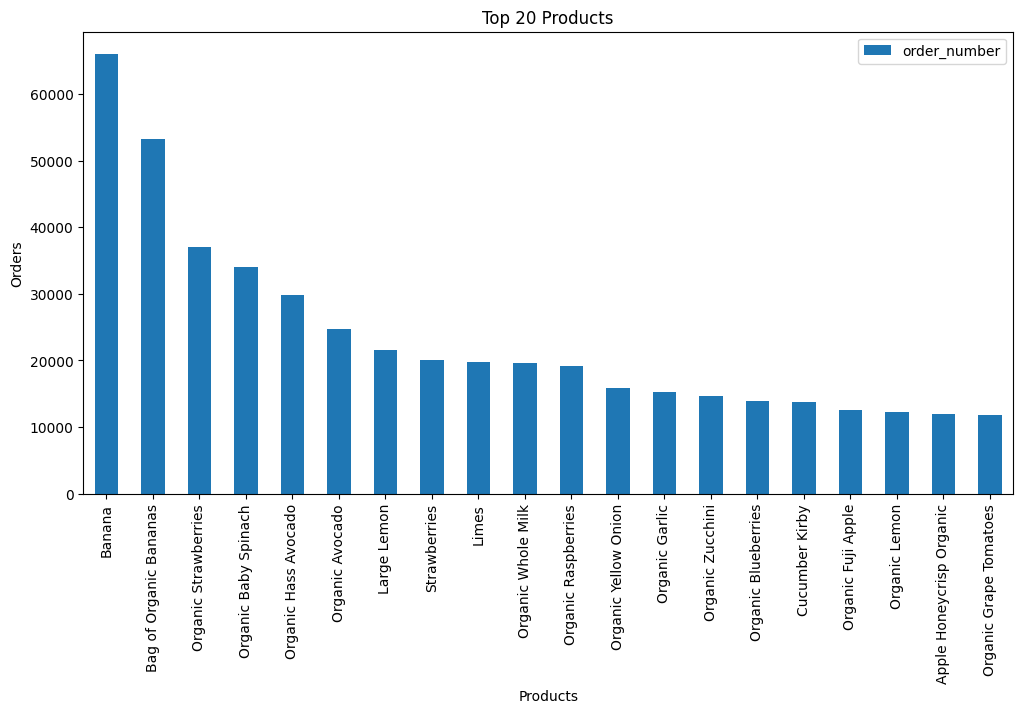

In [ ]:
#Analysis
#To identify the most frequently ordered products, the number of occurrences of each product_id was calculated using the order_products table. The top 20 products were then selected and merged with the products dataset to obtain the corresponding product names.

top_20_products = order_products['product_id'].value_counts().head(20)

top_20_df = top_20_products.reset_index() #Convert on dataframe to do "merge"
top_20_df.columns = ['product_id', 'order_number']

top_20_products_name = top_20_df.merge(products[['product_id', 'product_name']], on='product_id')

top_20_products_name.plot(kind='bar',
                          figsize=(12,6) ,
                          title='Top 20 Products',
                          xlabel="Products",
                          ylabel='Orders',
                          x='product_name',
                          y='order_number'
                                       
)
plt.show()

The results show that Banana is the most frequently ordered product by a considerable margin, followed by Bag of Organic Bananas. Several fresh produce items also appear among the most popular products, including Organic Strawberries, Organic Baby Spinach, Organic Hass Avocado, Organic Avocado, Large Lemon, and Strawberries.

A notable pattern is the dominant presence of fruits and vegetables among the top-ranked products. Additionally, many of the most frequently ordered items are organic alternatives, suggesting a strong customer preference for fresh and organic food products.

While Banana and Bag of Organic Bananas clearly stand out as the two most popular products, the remaining products show relatively similar order frequencies, indicating consistent demand across a variety of grocery staples.

# Conclusion

The analysis reveals that fresh produce dominates the list of the most frequently ordered products. Bananas, organic bananas, strawberries, avocados, spinach, lemons, and other fruits and vegetables represent a significant portion of the top 20 products. Furthermore, the high presence of organic products suggests that many customers prioritize healthier or organic food options when shopping. Overall, the results indicate that fresh produce is the primary driver of order volume within the Instacart platform.

In [94]:
top_20_products_name

,product_id,order_number,product_name
0,24852,66050,Banana
1,13176,53297,Bag of Organic Bananas
2,21137,37039,Organic Strawberries
3,21903,33971,Organic Baby Spinach
4,47209,29773,Organic Hass Avocado
5,47766,24689,Organic Avocado
6,47626,21495,Large Lemon
7,16797,20018,Strawberries
8,26209,19690,Limes
9,27845,19600,Organic Whole Milk


## How Many Items Do Customers Typically Purchase per Order?

# Objective

The purpose of this analysis is to determine how many products customers typically include in a single order and to examine the overall distribution of order sizes. Understanding this behavior provides insight into purchasing patterns and the typical volume of products purchased during each shopping session.

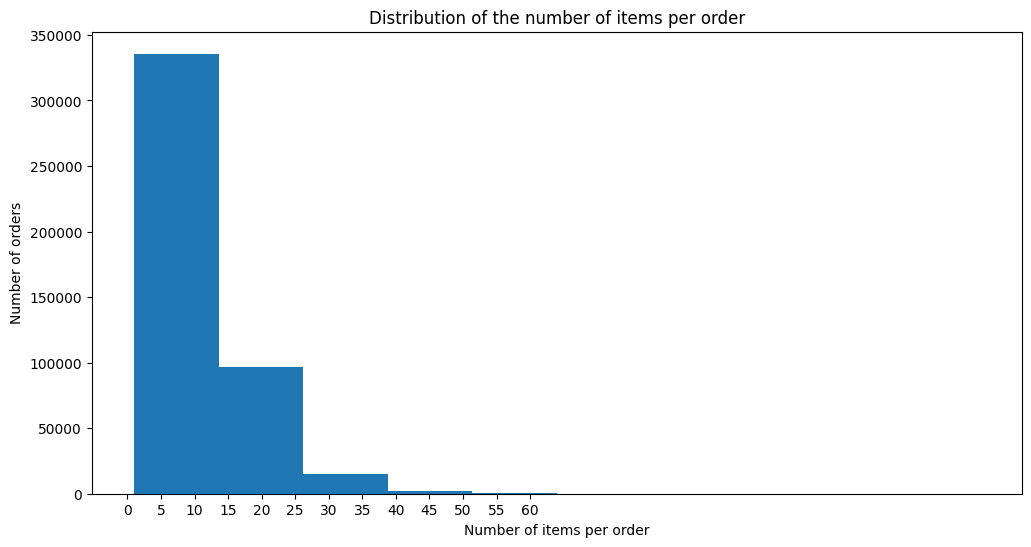

In [ ]:
# Analysis
# To calculate the number of items per order, the order_products dataset was grouped by order_id, and the number of products associated with each order was counted.

items_by_order = order_products.groupby('order_id').size()

items_by_order.plot(kind='hist',
                    figsize=(12,6),
                    title='Distribution of the number of items per order',
                    ylabel= 'Number of orders',
                    xlabel='Number of items per order',
                    xticks=(range(0,65,5))

)
plt.show()

The histogram shows that most orders contain a relatively small number of products. The highest concentration of orders appears between approximately 1 and 15 items, indicating that customers generally place modest-sized orders.

As the number of items per order increases, the frequency of orders declines substantially. Orders containing more than 30 products are considerably less common, while very large orders containing 50 or more items occur only rarely.

The distribution is positively skewed (right-skewed), with a long tail extending toward larger order sizes. This pattern indicates that while most customers purchase a limited number of items per order, a smaller group of customers occasionally places significantly larger orders.

# Conclusion

The analysis indicates that customers typically purchase a relatively small number of items in each order, with most orders containing fewer than 15 products. The distribution is strongly right-skewed, meaning that large orders exist but represent a small proportion of total purchases. Overall, customer purchasing behavior is characterized by smaller, routine orders rather than large bulk purchases, although a minority of customers occasionally submit substantially larger orders.

## What Are the Top 20 Most Frequently Reordered Products?

# Objective

The purpose of this analysis is to identify the products that customers reorder most frequently. Examining reordered items provides insight into customer loyalty, purchasing habits, and the products that are consistently replenished over time.

C:\Users\Crist\AppData\Local\Temp\ipykernel_24772\1090395069.py:5: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  top_20_reordered_products.colums = ['product_id', 'Reordered_Qty']


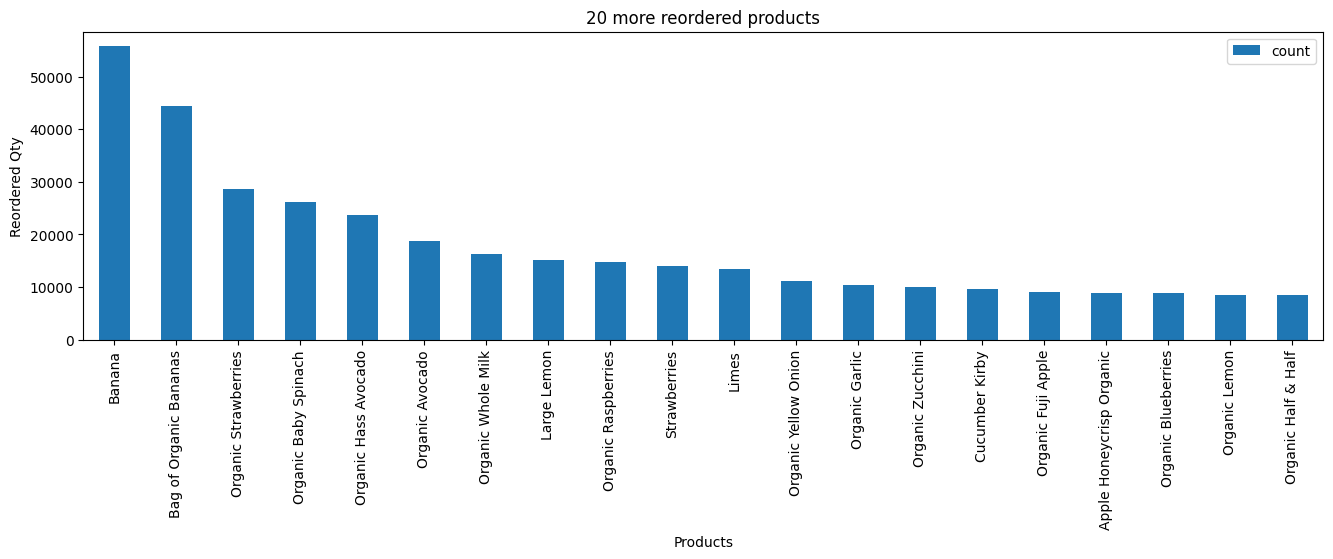

In [ ]:
#Analysis
#To determine the most frequently reordered products, only records where reordered = 1 were selected from the order_products dataset. The number of reorders for each product was then calculated, and the top 20 products were merged with the products table to retrieve their names.

reordered_products = order_products[order_products['reordered'] == 1]
top_20_reordered_products = reordered_products['product_id'].value_counts().head(20)

top_20_reordered_products = top_20_reordered_products.reset_index()
top_20_reordered_products.colums = ['product_id', 'Reordered_Qty']
results_top20 = top_20_reordered_products.merge(products[['product_id', 'product_name']], on='product_id')


results_top20.plot(kind='bar',
                   figsize=(16,4),
                   title='20 more reordered products',
                   xlabel='Products',
                   ylabel='Reordered Qty',
                   x='product_name',
                   y='count'
                   )
                
plt.show()


The results indicate that Banana is the most frequently reordered product by a substantial margin, followed by Bag of Organic Bananas. Several other fresh produce items also rank among the most reordered products, including Organic Strawberries, Organic Baby Spinach, Organic Hass Avocado, Organic Avocado, and Large Lemon.

A clear pattern emerges from the chart: the majority of the most reordered products are fresh fruits, vegetables, and organic items. These products are commonly consumed on a regular basis and therefore require frequent replenishment, which helps explain their high reorder rates.

The list of top reordered products is very similar to the list of the most frequently ordered products, suggesting that customers repeatedly purchase the same staple grocery items rather than frequently switching to different products.

# Conclusion

The analysis reveals that fresh produce dominates the list of the most frequently reordered products. Bananas, organic bananas, strawberries, avocados, spinach, lemons, and other everyday grocery staples show the highest levels of customer repurchase behavior. This pattern suggests strong customer loyalty toward these products and indicates that recurring household essentials are a major driver of repeat purchases on the Instacart platform. The high reorder frequency of these items reflects consistent consumption habits and highlights their importance in customer retention and long-term purchasing behavior.

## What Proportion of Orders for Each Product Are Reorders?

# Objective

The purpose of this analysis is to measure customer repurchase behavior for each product. Specifically, the goal is to determine the proportion of a product's orders that were placed as reorders, allowing us to identify which products are more likely to be purchased repeatedly by customers.

# Analysis

To calculate the reorder proportion for each product, the total number of orders and the total number of reorders were computed for every product_id. The reorder rate was then calculated as:

Reorder Proportion = Total Reorders / Total Orders

The resulting dataset was merged with the products table to include product names.

In [ ]:
total_orders = order_products.groupby('product_id').size()
total_reorders = order_products[order_products['reordered'] == 1].groupby('product_id').size()

proportions = pd.DataFrame({
    'total_orders': total_orders,
    'total_reorders': total_reorders
})

proportions['proportion_reorder'] = proportions['total_reorders'] / proportions['total_orders']
proportions = proportions.fillna(0)  # Replace NaN with 0 in products that have never been reordered

proportions = proportions.reset_index() #Reset_index to create a new numeric index
final_dateframe = proportions.merge(products[['product_id', 'product_name']], on='product_id') #Merge products dateframe to know "product_name"
results = final_dateframe[['product_id', 'product_name', 'total_orders', 'total_reorders', 'proportion_reorder']]

results.head(20)                                   

,product_id,product_name,total_orders,total_reorders,proportion_reorder
0,1,Chocolate Sandwich Cookies,280,158.0,0.564286
1,2,All-Seasons Salt,11,0.0,0.000000
2,3,Robust Golden Unsweetened Oolong Tea,42,31.0,0.738095
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,49,25.0,0.510204
4,7,Pure Coconut Water With Orange,2,1.0,0.500000
5,8,Cut Russet Potatoes Steam N' Mash,19,6.0,0.315789
6,9,Light Strawberry Blueberry Yogurt,21,16.0,0.761905
7,10,Sparkling Orange Juice & Prickly Pear Beverage,337,151.0,0.448071
8,11,Peach Mango Juice,16,10.0,0.625000
9,12,Chocolate Fudge Layer Cake,41,16.0,0.390244


The resulting table shows, for each product:

Product ID
Product Name
Total Orders
Total Reorders
Reorder Proportion

Several products display relatively high reorder proportions, indicating that customers frequently purchase them again after an initial order. For example, products such as Light Strawberry Blueberry Yogurt, Robust Golden Unsweetened Oolong Tea, and Salted Caramel Lean Protein & Fiber Bar exhibit reorder rates above 60%, suggesting strong customer loyalty and repeat purchasing behavior.

Conversely, many products have reorder proportions close to zero, meaning they were either purchased only once or rarely repurchased. This behavior may reflect specialty, seasonal, or less frequently consumed products.

It is also important to note that products with very few total orders can produce extreme reorder proportions. For example, a product ordered only twice and reordered once would show a reorder proportion of 50%, despite having a very small purchase history. Therefore, reorder rates should be interpreted alongside the total number of orders.

# Conclusion

The analysis demonstrates that reorder behavior varies significantly across products. While some products are consistently repurchased and show high customer loyalty, others are seldom reordered after the initial purchase. Products with high reorder proportions are likely staple or frequently consumed items, making them valuable indicators of long-term customer demand. Analyzing both reorder proportions and total order volume provides a more complete understanding of product performance and customer purchasing habits on the Instacart platform.

## What Proportion of Ordered Products Are Reordered for Each Customer?

# Objective

The purpose of this analysis is to evaluate customer purchasing behavior by calculating the proportion of products that were reordered by each customer. This metric helps measure customer loyalty and identifies how frequently customers repurchase products they have previously bought.

# Analysis

To calculate the reorder proportion for each customer, the order_products and instacart_orders datasets were merged using order_id to associate every product purchased with a specific user_id.

Next, the total number of products ordered and the total number of reordered products were calculated for each customer. The reorder proportion was then computed using the following formula:

Reorder Proportion=Total Reordered Products / Total Products Ordered

In [193]:
productos_con_usuario = order_products.merge(instacart_orders[['order_id', 'user_id']], on='order_id')# Unir para obtener el user_id en cada producto pedido
productos_con_usuario = order_products.merge(instacart_orders[['order_id', 'user_id']], on='order_id')

# Total de productos pedidos por cada cliente
total_productos_por_usuario = productos_con_usuario.groupby('user_id').size()

# Total de productos reordenados por cada cliente
total_reordenados_por_usuario = productos_con_usuario[productos_con_usuario['reordered'] == 1].groupby('user_id').size()

# Crear DataFrame con ambas métricas
proporcion_reorden_usuario = pd.DataFrame({
    'total_productos': total_productos_por_usuario,
    'total_reordenados': total_reordenados_por_usuario
})

# Calcular proporción
proporcion_reorden_usuario['proporcion_reorden'] = proporcion_reorden_usuario['total_reordenados'] / proporcion_reorden_usuario['total_productos']
proporcion_reorden_usuario = proporcion_reorden_usuario.fillna(0)  # En caso de usuarios sin reórdenes

print(proporcion_reorden_usuario.head(10)) 

         total_productos  total_reordenados  proporcion_reorden
user_id                                                        
2                     26                1.0            0.038462
4                      2                0.0            0.000000
5                     12                8.0            0.666667
6                      4                0.0            0.000000
7                     14               13.0            0.928571
11                    15                3.0            0.200000
12                    12                3.0            0.250000
13                    23               13.0            0.565217
14                    61               22.0            0.360656
15                    13                7.0            0.538462


The resulting table provides, for each customer:

Total products ordered
Total reordered products
Reorder proportion

The sample results show substantial variation among customers. For example:

User 7 has a reorder proportion of approximately 0.93, indicating that nearly all purchased products were previously ordered items.
User 5 has a reorder proportion of approximately 0.67, showing a strong tendency to repurchase products.
Users 4 and 6 have a reorder proportion of 0.00, indicating that none of their purchases were classified as reorders.
Several customers fall between these extremes, reflecting different shopping habits and levels of product loyalty.

These differences suggest that some customers consistently purchase the same products, while others prefer greater variety or may be relatively new users with limited purchasing history.

# Conclusion

The analysis reveals significant variation in reorder behavior across customers. Some customers display very high reorder proportions, indicating strong loyalty to a consistent set of products, while others rarely or never reorder items. Overall, the reorder proportion is an effective measure of customer retention and purchasing consistency. Customers with high reorder rates are likely habitual shoppers who repeatedly purchase staple products, whereas lower reorder rates may reflect exploratory purchasing behavior or less established shopping patterns. This metric provides valuable insight into customer loyalty and long-term engagement with the platform.

## What Are the Top 20 Products Most Frequently Added First to the Shopping Cart?

# Objective

The purpose of this analysis is to identify the products that customers most frequently add as the first item in their shopping cart. Since the first product added often reflects the primary purpose of a shopping session, this analysis provides insight into the products that commonly initiate customer purchases.

# Analysis

To identify these products, only records where add_to_cart_order = 1 were selected, indicating that the product was the first item added to the cart. The products were then ranked by frequency, and product names were retrieved by merging the results with the products dataset.

In [194]:
primeros_productos = order_products[order_products['add_to_cart_order'] == 1]

conteo_primeros = primeros_productos['product_id'].value_counts().head(20).reset_index()
conteo_primeros.columns = ['product_id', 'veces_agregado_primero']


resultado = conteo_primeros.merge(products[['product_id', 'product_name']], on='product_id')
print(resultado[['product_id', 'product_name', 'veces_agregado_primero']])


    product_id                 product_name  veces_agregado_primero
0        24852                       Banana                   15562
1        13176       Bag of Organic Bananas                   11026
2        27845           Organic Whole Milk                    4363
3        21137         Organic Strawberries                    3946
4        47209         Organic Hass Avocado                    3390
5        21903         Organic Baby Spinach                    3336
6        47766              Organic Avocado                    3044
7        19660                 Spring Water                    2336
8        16797                 Strawberries                    2308
9        27966          Organic Raspberries                    2024
10       44632   Sparkling Water Grapefruit                    1914
11       49235          Organic Half & Half                    1797
12       47626                  Large Lemon                    1737
13         196                         Soda     

The results show that Banana is the product most frequently added first to a shopping cart, with more than 15,000 occurrences. It is followed by Bag of Organic Bananas, which was the first item added over 11,000 times.

Other frequently selected first-cart items include:

Organic Whole Milk
Organic Strawberries
Organic Hass Avocado
Organic Baby Spinach
Organic Avocado
Spring Water
Strawberries
Organic Raspberries

A clear pattern emerges from the rankings: fresh produce and everyday grocery staples dominate the list. Fruits, vegetables, milk, and other commonly consumed household products appear far more often than processed or specialty items.

Additionally, many of the top products are organic alternatives, reinforcing the trend observed in previous analyses that customers show a strong preference for organic food products.

# Conclusion

The analysis reveals that customers most often begin their shopping sessions with staple grocery items, particularly fresh produce and organic products. Banana and Bag of Organic Bananas are by far the most common first items added to carts, suggesting that these products play a central role in many shopping trips. Overall, the results indicate that customers frequently build their orders around a core set of essential products, with fruits, vegetables, and dairy products serving as the primary drivers of shopping activity on the Instacart platform.

## Final Conclusion

This project analyzed Instacart customer purchasing behavior by cleaning the data, handling missing values and duplicates, and exploring ordering patterns. The results showed that customers tend to place orders during daytime hours, particularly in the late morning and early afternoon, and follow recurring weekly and monthly shopping routines.

The analysis also revealed that most customers place a relatively small number of orders and purchase a limited number of items per order. However, a smaller group of highly engaged customers generates a large share of repeat purchases.

At the product level, fresh produce and organic items such as Banana, Bag of Organic Bananas, Organic Strawberries, and Organic Avocados consistently ranked among the most ordered, most reordered, and most frequently selected first-cart products. Additionally, reorder rates demonstrated strong customer loyalty toward everyday grocery staples.

Overall, the findings indicate that Instacart customers exhibit predictable shopping habits centered around recurring purchases of fresh and organic products. These insights can support inventory management, demand forecasting, and personalized recommendation strategies.